# CryptoShieldAI: Ethereum Account Fraud Detection

**Mini Project**

In this project, I use machine learning to predict the `flag` of an Ethereum account from its transaction-related features.

The notebook includes data exploration, a few feature engineering steps, and a comparison of Logistic Regression, Random Forest and XGBoost.

>

## 1. Import libraries

In [155]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import warnings

warnings.filterwarnings('ignore')



## 2. Load the dataset

Upload DataSet to the Colab session.

In [156]:
df = pd.read_csv("/content/crypto_dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (12146, 33)


,address,flag,minTimeBetweenSentTnx,maxTimeBetweenSentTnx,avgTimeBetweenSentTnx,minTimeBetweenRecTnx,maxTimeBetweenRecTnx,avgTimeBetweenRecTnx,lifetime,sentTransactions,...,totalEtherBalance,activityDays,dailyMax,ratioRecSent,ratioSentTotal,ratioRecTotal,giniSent,giniRec,txFreq,stdBalanceEth
0,0x0000000000007f150bd6f54c40a34d7c3d5e9f56,0,0,0,0.0,0,1603484647,160362.490300,2,0,...,6.000000e+02,2,5485,10000.0,0.0,0.999900,0.0,9.998650e-01,5000.000000,6.053926e+01
1,0x0000000000085d4780b73119b644ae5ecd22b376,0,0,0,0.0,0,189091,166.377738,20,0,...,0.000000e+00,20,1387,9999.0,0.0,0.999800,0.0,0.000000e+00,500.000000,0.000000e+00
2,0x00000000000a47b1298f18cf67de547bbe0d723f,0,0,0,0.0,0,1648811316,165460.505000,68,0,...,2.070000e-14,68,639,10000.0,0.0,0.999900,0.0,6.800000e-12,147.058823,7.010000e-15
3,0x00000000000e1d0dabf7b7c7b68866fc940d0db8,0,0,0,0.0,0,1633267765,314955.275000,333,0,...,0.000000e+00,333,83,5277.0,0.0,0.999811,0.0,3.990000e-17,15.846847,0.000000e+00
4,0x000000000035b5e5ad9019092c665357240f594e,0,0,0,0.0,0,1622688855,162405.740300,16,0,...,4.000000e+01,16,956,10000.0,0.0,0.999900,0.0,9.997250e-01,625.000000,1.016700e+01


## 3. Explore the data

In [157]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null values:")
df.info()

Rows and columns: (12146, 33)

Column names:
['address', 'flag', 'minTimeBetweenSentTnx', 'maxTimeBetweenSentTnx', 'avgTimeBetweenSentTnx', 'minTimeBetweenRecTnx', 'maxTimeBetweenRecTnx', 'avgTimeBetweenRecTnx', 'lifetime', 'sentTransactions', 'receivedTransactions', 'createdContracts', 'Average_of_numUniqSentAddress', 'Average_of_numUniqRecAddress', 'minValSent', 'maxValSent', 'avgValSent', 'minValReceived', 'maxValReceived', 'avgValReceived', 'totalTransactions', 'totalEtherSent', 'totalEtherReceived', 'totalEtherBalance', 'activityDays', 'dailyMax', 'ratioRecSent', 'ratioSentTotal', 'ratioRecTotal', 'giniSent', 'giniRec', 'txFreq', 'stdBalanceEth']

Data types and non-null values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12146 entries, 0 to 12145
Data columns (total 33 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   address                        12146 non-null  object 
 1   flag         

In [158]:
df.describe()

,flag,minTimeBetweenSentTnx,maxTimeBetweenSentTnx,avgTimeBetweenSentTnx,minTimeBetweenRecTnx,maxTimeBetweenRecTnx,avgTimeBetweenRecTnx,lifetime,sentTransactions,receivedTransactions,...,totalEtherBalance,activityDays,dailyMax,ratioRecSent,ratioSentTotal,ratioRecTotal,giniSent,giniRec,txFreq,stdBalanceEth
count,12146.000000,1.214600e+04,1.214600e+04,1.214600e+04,1.214600e+04,1.214600e+04,1.214600e+04,12146.000000,12146.000000,12146.000000,...,1.214600e+04,12146.000000,12146.000000,12146.000000,12146.000000,12146.000000,1.214600e+04,1.214600e+04,12146.000000,1.214600e+04
mean,0.424008,2.649065e+04,4.270947e+07,3.648564e+06,2.499426e+05,1.162226e+09,1.601823e+08,191.749630,517.366787,678.387617,...,-1.367650e+02,85.492343,209.392393,581.427949,0.458685,0.452111,4.341055e-01,4.104000e-01,64.605495,6.970988e+02
std,0.494212,7.167752e+05,2.510061e+08,4.121296e+07,3.403948e+06,7.159138e+08,2.329373e+08,299.970482,1875.017481,2253.808922,...,6.582241e+04,172.709068,974.655740,2206.404201,0.332333,0.317690,3.745526e-01,3.009740e-01,543.602564,2.432648e+04
min,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000,0.000000,0.000000,...,-5.348493e+06,1.000000,1.000000,0.000000,0.000000,0.000000,-6.740000e-17,-9.320000e-17,0.001145,0.000000e+00
25%,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.794640e+06,8.564709e+04,9.000000,1.000000,3.000000,...,-3.532467e-01,3.000000,2.000000,0.230311,0.142857,0.186526,0.000000e+00,9.707937e-02,0.277778,8.364961e-02
50%,0.000000,0.000000e+00,2.042395e+05,1.490919e+04,4.800000e+01,1.578994e+09,4.776982e+07,68.000000,6.000000,11.000000,...,1.563244e-03,15.000000,5.000000,0.620312,0.454545,0.375000,4.940496e-01,4.459279e-01,1.080336,9.335405e-01
75%,1.000000,8.000000e+01,1.845179e+06,1.391289e+05,7.147500e+02,1.640623e+09,2.192212e+08,251.000000,70.000000,55.000000,...,4.064367e-02,85.000000,24.000000,2.741071,0.773654,0.714286,8.008659e-01,6.347963e-01,4.000000,6.826739e+00
max,1.000000,6.198813e+07,1.658260e+09,8.291299e+08,1.508562e+08,1.658260e+09,8.309932e+08,2293.000000,10000.000000,10000.000000,...,1.847901e+06,1912.000000,10000.000000,10000.000000,0.999900,0.999900,9.998963e-01,9.998940e-01,10000.000000,2.038484e+06


In [159]:
print("Missing values in each column:")
display(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

Missing values in each column:


,0
address,0
flag,0
minTimeBetweenSentTnx,0
maxTimeBetweenSentTnx,0
avgTimeBetweenSentTnx,0
minTimeBetweenRecTnx,0
maxTimeBetweenRecTnx,0
avgTimeBetweenRecTnx,0
lifetime,0
sentTransactions,0


Duplicate rows: 0


Target value counts:


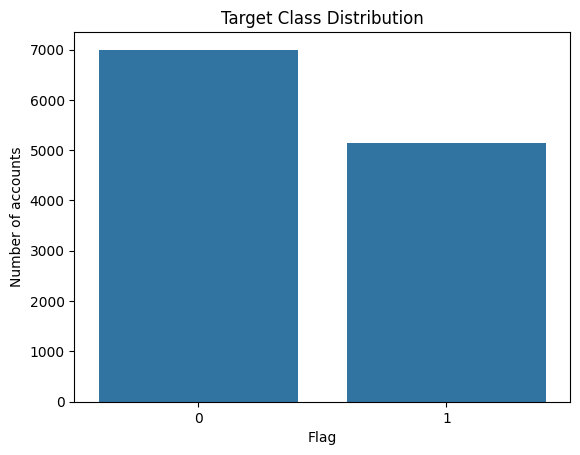

In [160]:
print("Target value counts:")


sns.countplot(data=df, x="flag")
plt.title("Target Class Distribution")
plt.xlabel("Flag")
plt.ylabel("Number of accounts")
plt.show()

In [161]:
df.dtypes

,0
address,object
flag,int64
minTimeBetweenSentTnx,int64
maxTimeBetweenSentTnx,int64
avgTimeBetweenSentTnx,float64
minTimeBetweenRecTnx,int64
maxTimeBetweenRecTnx,int64
avgTimeBetweenRecTnx,float64
lifetime,int64
sentTransactions,int64


## 4. Visualize some features

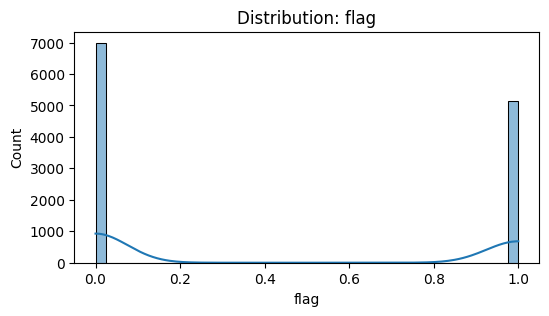

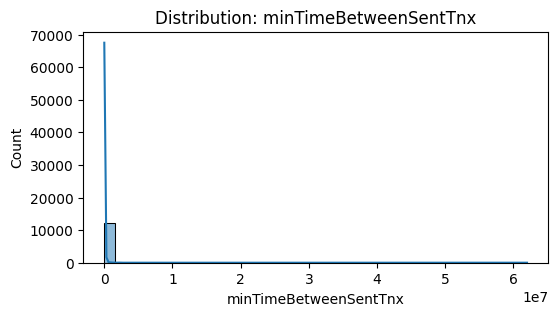

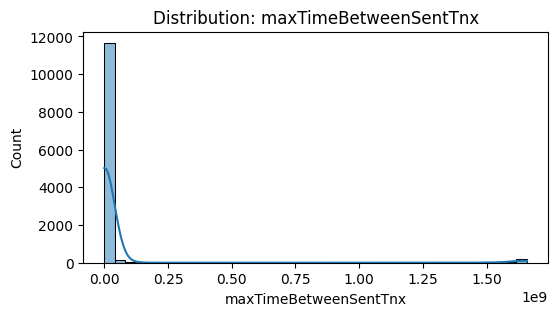

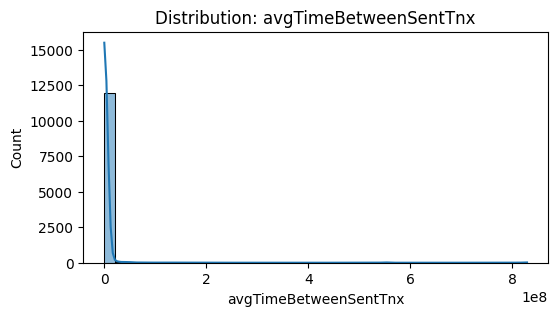

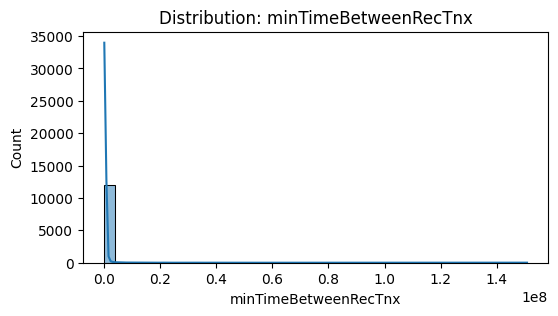

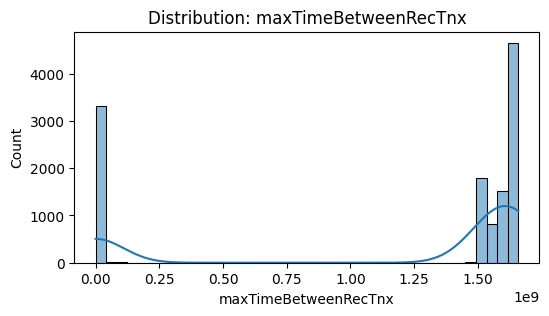

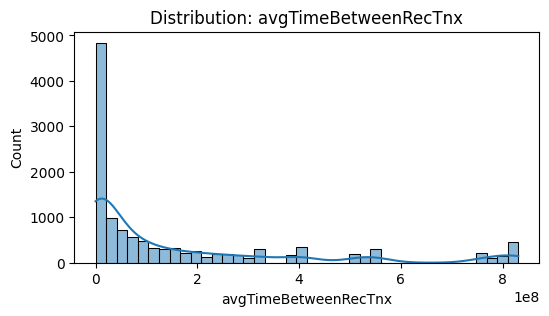

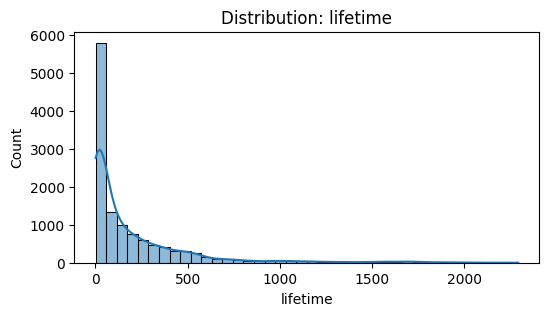

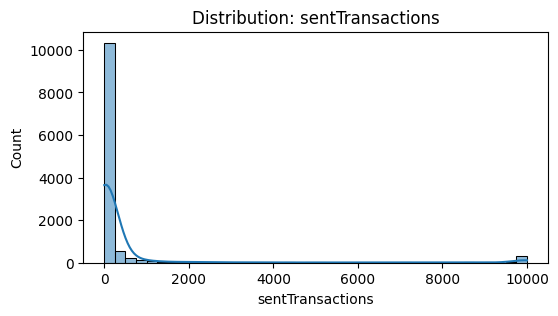

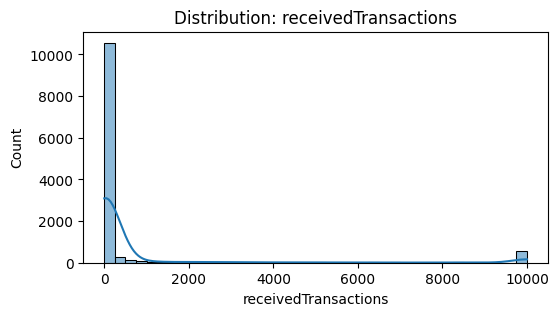

In [162]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()

for col in numeric_cols[:10]:
    plt.figure(figsize=(6, 3))
    sns.histplot(data=df, x=col, bins=40, kde=True)
    plt.title(f"Distribution: {col}")

    plt.show()

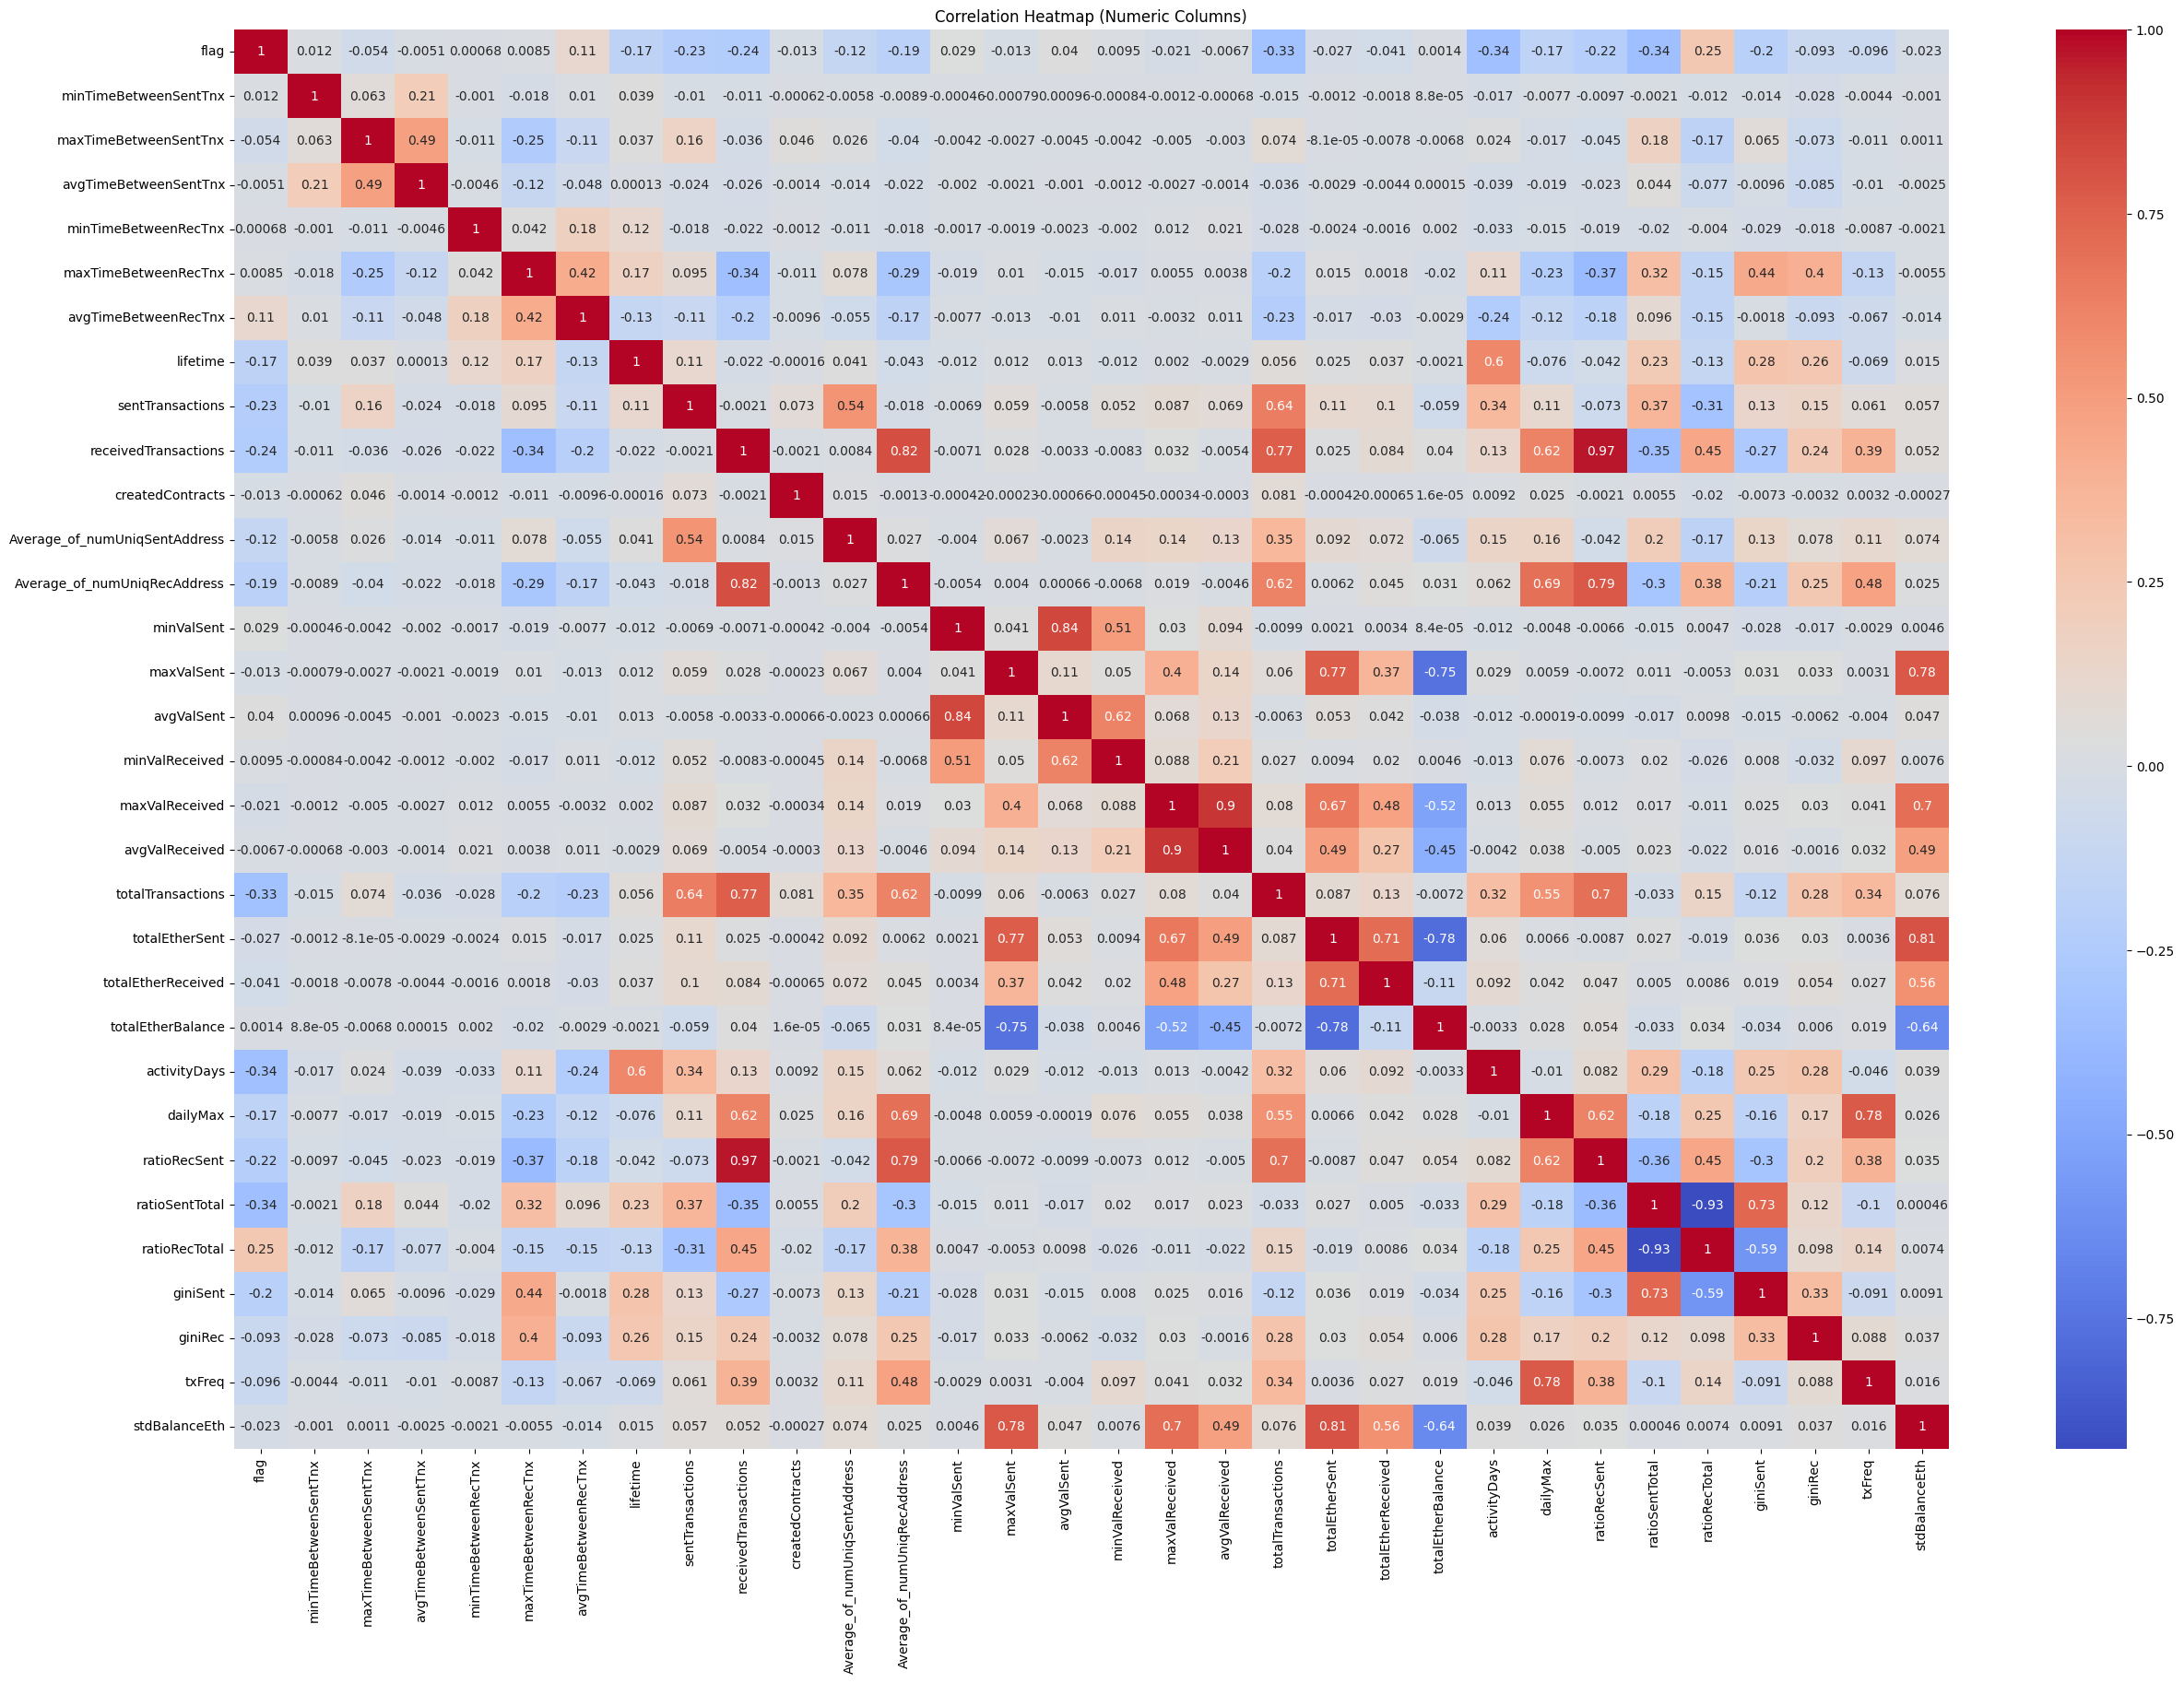

In [163]:
plt.figure(figsize=(30, 20))
corr = df.corr(numeric_only = True)
sns.heatmap(corr, cmap="coolwarm",  annot=True)
plt.title("Correlation Heatmap (Numeric Columns)")
plt.show()

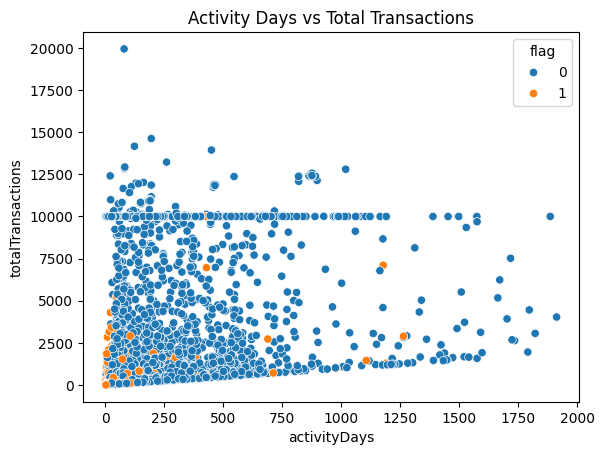

In [164]:
sns.scatterplot(data=df, x="activityDays", y="totalTransactions", hue="flag")
plt.title("Activity Days vs Total Transactions")
plt.show()

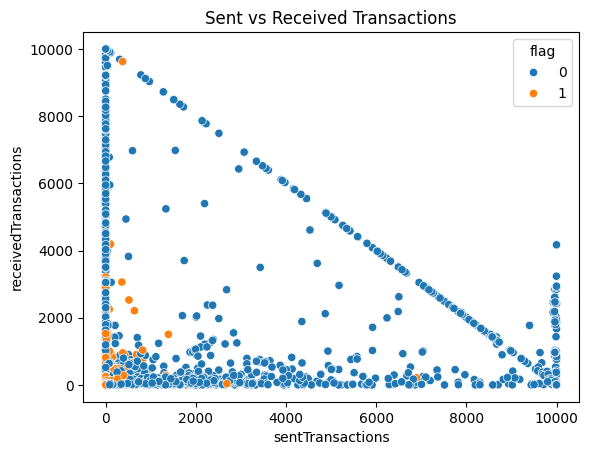

In [165]:
sns.scatterplot(data=df, x="sentTransactions", y="receivedTransactions", hue="flag")
plt.title("Sent vs Received Transactions")
plt.show()

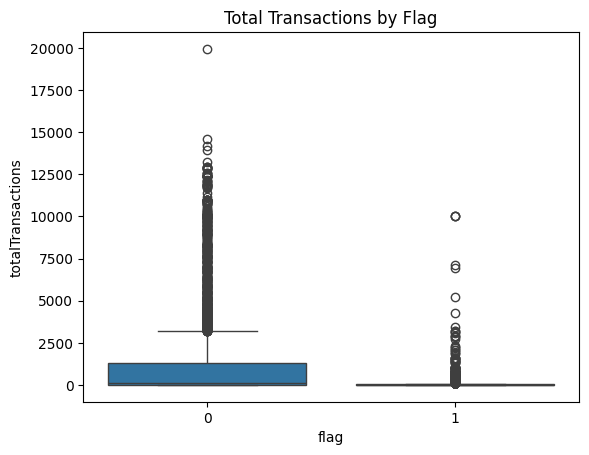

In [166]:
sns.boxplot(data=df, x="flag", y="totalTransactions")
plt.title("Total Transactions by Flag")
plt.show()

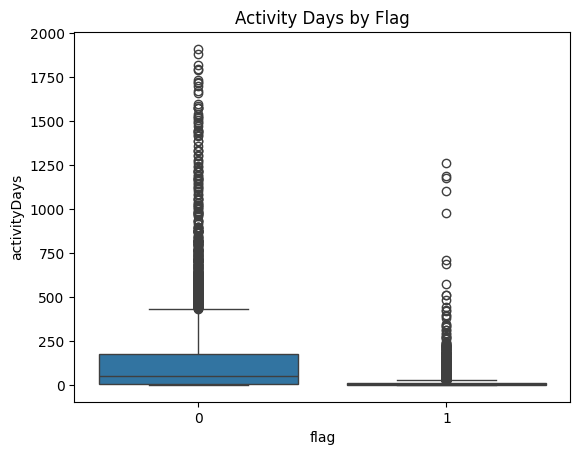

In [167]:
sns.boxplot(data=df, x="flag", y="activityDays")
plt.title("Activity Days by Flag")
plt.show()

<Axes: xlabel='ratioSentTotal', ylabel='ratioRecTotal'>

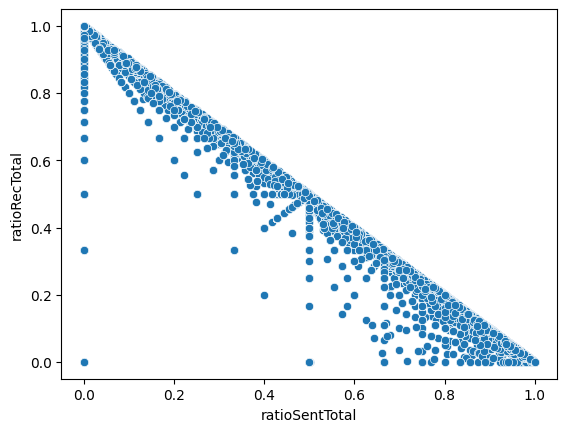

In [168]:

sns.scatterplot(data = df, x = 'ratioSentTotal', y = 'ratioRecTotal')

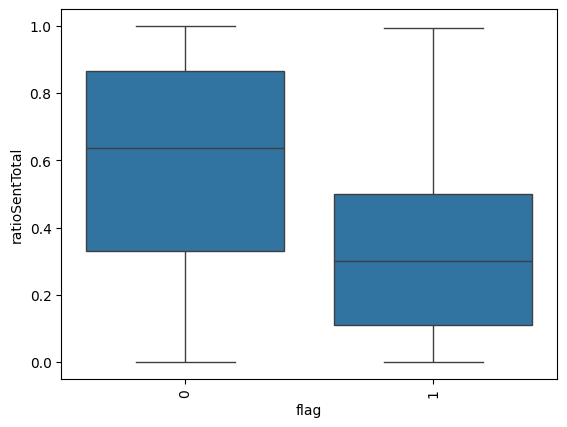

In [169]:
sns.boxplot(data=df, x='flag', y='ratioSentTotal')
plt.xticks(rotation=90)
plt.show()

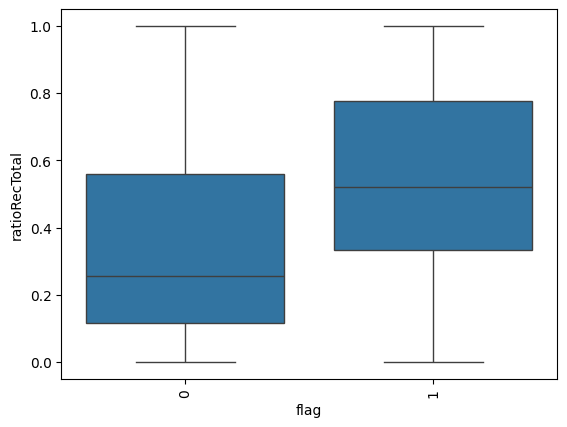

In [170]:
sns.boxplot(data=df, x='flag', y='ratioRecTotal')
plt.xticks(rotation=90)
plt.show()

## 5. Prepare the data

The `flag` column is the value we want to predict. The `address` column identifies an account, so I do not use it as a model feature.

In [171]:
X = df.drop(columns = ['flag'], axis=1)
y = df['flag']

y = df['flag'].astype(int)
X = df.drop(columns=['flag', 'address'])

X = X.dropna(axis=1, how='all')
display(y.value_counts().sort_index().to_frame("count"))

,count
flag,
0,6996
1,5150


## 6. Feature engineering

I create a few extra features from the transaction columns. These may help the models describe account activity in a different way.

In [172]:
X["netEtherFlow"] = X["totalEtherReceived"] - X["totalEtherSent"]

X["transactionsPerDay"] = X["totalTransactions"] / X["activityDays"].clip(lower=1)

X["transactionsPerLifetimeDay"] = X["totalTransactions"] / X["lifetime"].clip(lower=1)

X["averageSentValue"] = X["totalEtherSent"] / X["sentTransactions"].clip(lower=1)

X["averageReceivedValue"] = X["totalEtherReceived"] / X["receivedTransactions"].clip(lower=1)

X["transactionCountRatio"] = (X["receivedTransactions"] + 1) / (X["sentTransactions"] + 1)

X["averageValueDifference"] = X["avgValReceived"] - X["avgValSent"]

X = X.replace([np.inf, -np.inf], np.nan)

print("Feature count after feature engineering:", X.shape[1])
display(X.head())

Feature count after feature engineering: 38


,minTimeBetweenSentTnx,maxTimeBetweenSentTnx,avgTimeBetweenSentTnx,minTimeBetweenRecTnx,maxTimeBetweenRecTnx,avgTimeBetweenRecTnx,lifetime,sentTransactions,receivedTransactions,createdContracts,...,giniRec,txFreq,stdBalanceEth,netEtherFlow,transactionsPerDay,transactionsPerLifetimeDay,averageSentValue,averageReceivedValue,transactionCountRatio,averageValueDifference
0,0,0,0.0,0,1603484647,160362.490300,2,0,10000,0,...,9.998650e-01,5000.000000,6.053926e+01,6.000000e+02,5000.000000,5000.000000,0.0,6.000000e-02,10001.0,0.060
1,0,0,0.0,0,189091,166.377738,20,0,9999,1,...,0.000000e+00,500.000000,0.000000e+00,0.000000e+00,500.000000,500.000000,0.0,0.000000e+00,10000.0,0.000
2,0,0,0.0,0,1648811316,165460.505000,68,0,10000,0,...,6.800000e-12,147.058823,7.010000e-15,2.070000e-14,147.058824,147.058824,0.0,2.070000e-18,10001.0,0.000
3,0,0,0.0,0,1633267765,314955.275000,333,0,5277,0,...,3.990000e-17,15.846847,0.000000e+00,0.000000e+00,15.846847,15.846847,0.0,0.000000e+00,5278.0,0.000
4,0,0,0.0,0,1622688855,162405.740300,16,0,10000,0,...,9.997250e-01,625.000000,1.016700e+01,4.000000e+01,625.000000,625.000000,0.0,4.000000e-03,10001.0,0.004


## 7. Split the dataset

I use a stratified 60% training, 20% validation and 20% test split. Stratification keeps the class proportions similar across the splits. The test set is held back for the final comparison.

In [173]:

from sklearn.model_selection import train_test_split

# Split into 60% training and 40% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Split the remaining 40% equally into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Testing set:", X_test.shape, y_test.shape)

print("\nClass proportions (train):")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nClass proportions (test):")
print(y_test.value_counts(normalize=True).sort_index().round(3))


Training set: (7287, 38) (7287,)
Validation set: (2429, 38) (2429,)
Testing set: (2430, 38) (2430,)

Class proportions (train):
flag
0    0.576
1    0.424
Name: proportion, dtype: float64

Class proportions (test):
flag
0    0.576
1    0.424
Name: proportion, dtype: float64


In [174]:


from sklearn.preprocessing import StandardScaler

# Keep unscaled data for Random Forest and XGBoost
X_train_tree = X_train.copy()
X_val_tree = X_val.copy()
X_test_tree = X_test.copy()

# Scale features for Logistic Regression
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

feature_names = X.columns.tolist()

print("Preprocessing complete.")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)




Preprocessing complete.
Training: (7287, 38)
Validation: (2429, 38)
Testing: (2430, 38)


## 8. Train Logistic Regression

Logistic Regression is the baseline model. It uses the scaled features.

In [175]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=2000, random_state=42)
lr_model.fit(X_train, y_train)
print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


## 9. Train Random Forest

Random Forest combines predictions from many decision trees.

In [176]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_tree, y_train)
print("Random Forest model trained successfully.")

Random Forest model trained successfully.


## 10. Train XGBoost

XGBoost is a gradient-boosted tree model.

In [177]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)
xgb_model.fit(X_train_tree, y_train)
print("XGBoost model trained successfully.")

XGBoost model trained successfully.


## 11. Compare the models

All three models are evaluated on the same held-out test rows. The models are trained only once, above. Accuracy is shown alongside precision, recall, F1-score and ROC-AUC so the comparison does not rely on accuracy alone.

In [178]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, roc_auc_score, balanced_accuracy_score
)

models = ["Logistic Regression", "Random Forest", "XGBoost"]
trained_models = [lr_model, rf_model, xgb_model]
X_test_for_model = [X_test, X_test_tree, X_test_tree]

predictions = []
results = []

for name, fitted_model, model_X_test in zip(
    models, trained_models, X_test_for_model
):
    pred = fitted_model.predict(model_X_test)
    predictions.append(pred)

    # Calculate metrics
    accuracy = accuracy_score(y_test, pred)
    precision = precision_score(y_test, pred, pos_label=1, zero_division=0)
    recall = recall_score(y_test, pred, pos_label=1, zero_division=0)
    f1 = f1_score(y_test, pred, pos_label=1, zero_division=0)

    probability = fitted_model.predict_proba(model_X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, probability)

    # Print normal metrics
    print("\n", name)
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-score:", round(f1, 4))

    # Store results
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision (flag=1)": precision,
        "Recall (flag=1)": recall,
        "F1-score (flag=1)": f1,
        "ROC-AUC": roc_auc
    })

results_df = pd.DataFrame(results).sort_values(
    "F1-score (flag=1)",
    ascending=False
)

display(results_df.round(4))


 Logistic Regression
Accuracy: 0.784
Precision: 0.7198
Recall: 0.8029
F1-score: 0.7591

 Random Forest
Accuracy: 0.9473
Precision: 0.9439
Recall: 0.9311
F1-score: 0.9374

 XGBoost
Accuracy: 0.9531
Precision: 0.9508
Recall: 0.9379
F1-score: 0.9443


,Model,Accuracy,Precision (flag=1),Recall (flag=1),F1-score (flag=1),ROC-AUC
2,XGBoost,0.9531,0.9508,0.9379,0.9443,0.9915
1,Random Forest,0.9473,0.9439,0.9311,0.9374,0.9857
0,Logistic Regression,0.7840,0.7198,0.8029,0.7591,0.8871


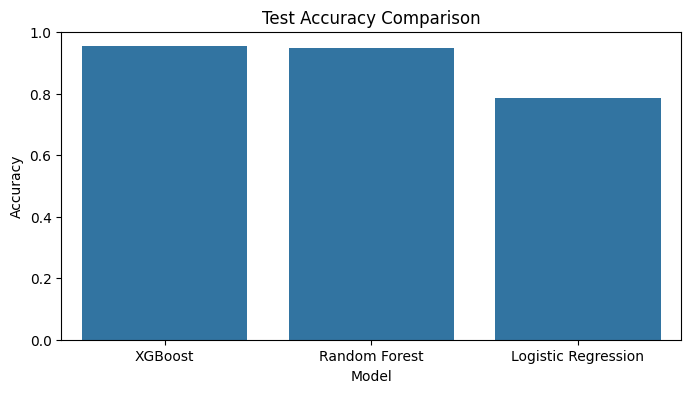

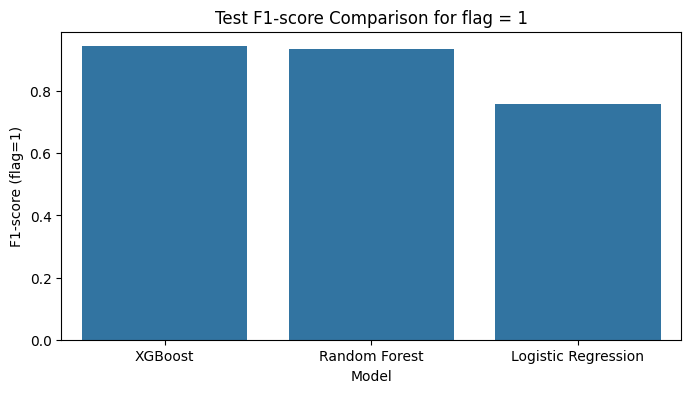

For fraud detection, review recall and precision as well as accuracy.


In [179]:
# Compare accuracy and F1-score.
plt.figure(figsize=(8, 4))
sns.barplot(data=results_df, x="Model", y="Accuracy")
plt.title("Test Accuracy Comparison")


plt.show()

plt.figure(figsize=(8, 4))
sns.barplot(data=results_df, x="Model", y="F1-score (flag=1)")
plt.title("Test F1-score Comparison for flag = 1")


plt.show()

print("For fraud detection, review recall and precision as well as accuracy.")

## 12. Confusion matrices

A confusion matrix shows correct and incorrect predictions for each class.

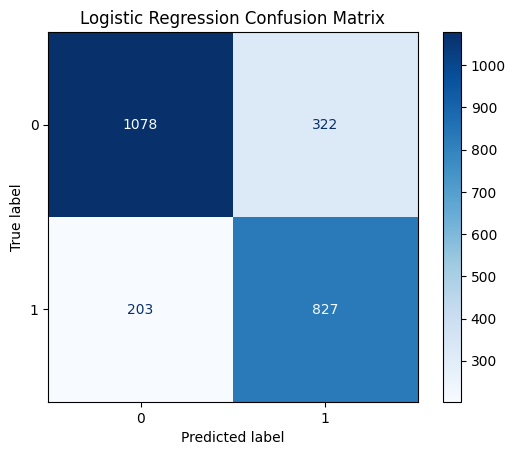

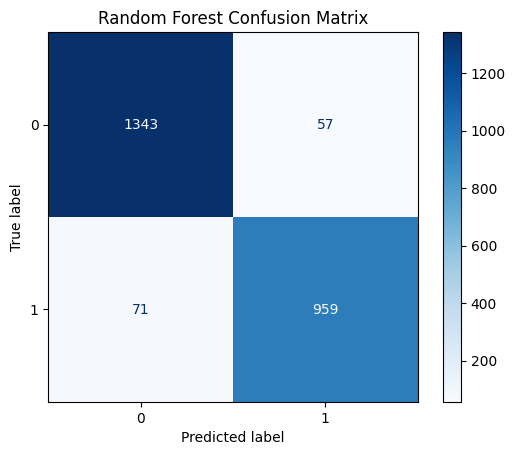

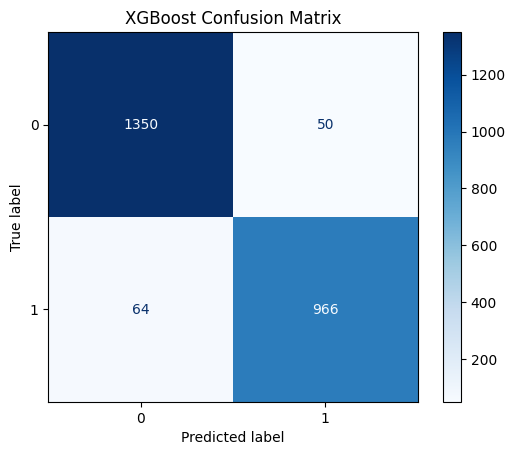

In [180]:
for name, pred in zip(models, predictions):
    cm = confusion_matrix(y_test, pred)
    display_cm = ConfusionMatrixDisplay(confusion_matrix=cm)
    display_cm.plot(cmap="Blues")
    plt.title(name + " Confusion Matrix")
    plt.show()

## 13. ROC curve

The ROC curve shows how well each model separates the two classes at different thresholds. A higher AUC generally means better separation.

<Figure size 700x500 with 0 Axes>

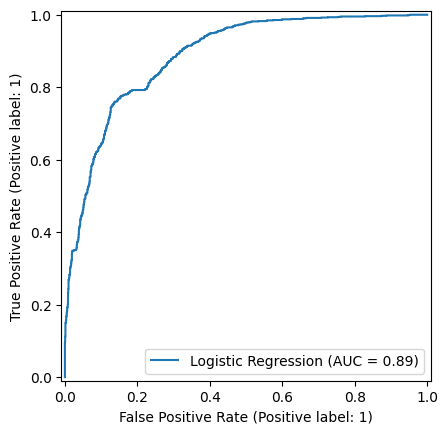

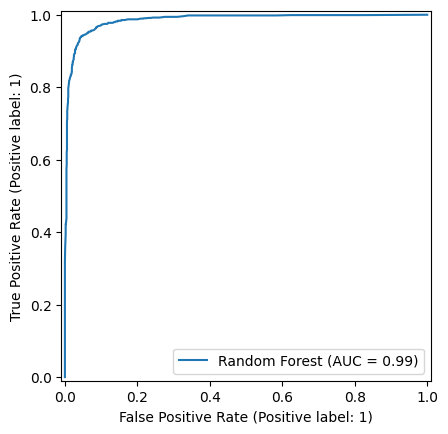

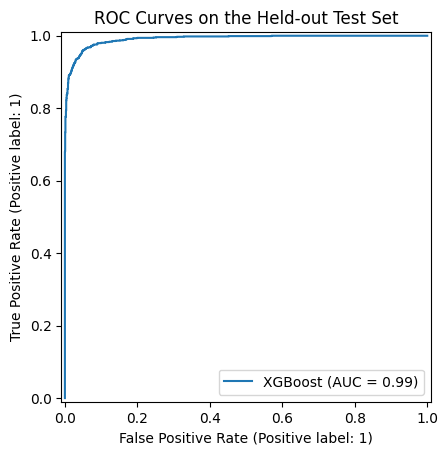

ROC-AUC scores:
Logistic Regression : 0.8871
Random Forest : 0.9857
XGBoost : 0.9915


In [181]:
plt.figure(figsize=(7, 5))

RocCurveDisplay.from_estimator(lr_model, X_test, y_test, name="Logistic Regression")
RocCurveDisplay.from_estimator(rf_model, X_test_tree, y_test, name="Random Forest")
RocCurveDisplay.from_estimator(xgb_model, X_test_tree, y_test, name="XGBoost")

plt.title("ROC Curves on the Held-out Test Set")
plt.show()

print("ROC-AUC scores:")
for name, fitted_model, model_X_test in zip(models, trained_models, X_test_for_model):
    probabilities = fitted_model.predict_proba(model_X_test)[:, 1]
    print(name, ":", round(roc_auc_score(y_test, probabilities), 4))

## 14. Feature importance

Random Forest feature importance gives a rough idea of which features the model used most when making predictions.

,Importance
maxTimeBetweenRecTnx,0.131896
averageSentValue,0.075641
avgValSent,0.065890
activityDays,0.064902
averageValueDifference,0.054247
totalTransactions,0.046644
minValSent,0.031866
Average_of_numUniqRecAddress,0.028075
lifetime,0.027500
sentTransactions,0.026348


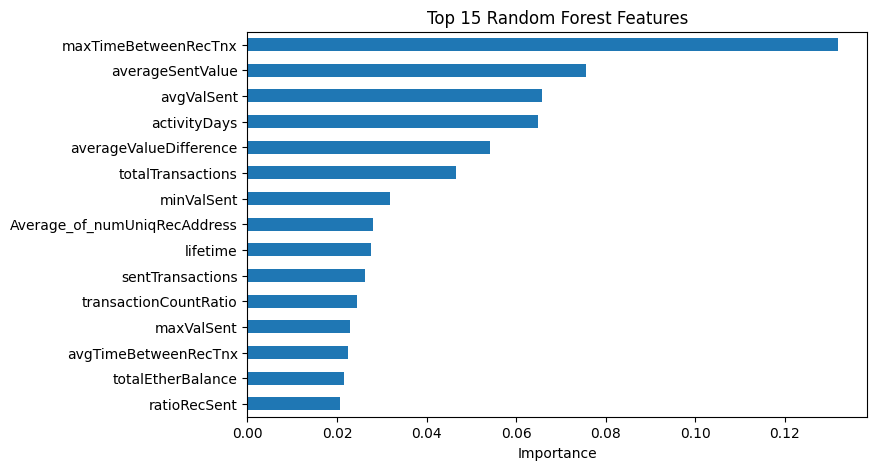


Feature importance is a model-specific diagnostic of what features comtribute most to prediction


In [182]:
importance = pd.Series(rf_model.feature_importances_, index=feature_names)
importance = importance.sort_values(ascending=False).head(15)

display(importance.to_frame("Importance"))
importance.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 15 Random Forest Features")
plt.xlabel("Importance")
plt.show()

print()
print("Feature importance is a model-specific diagnostic of what features comtribute most to prediction")

## 15. Actual and predicted values

This table shows the actual target value beside each model's prediction for a small sample of test rows.

In [183]:
comparison = pd.DataFrame({
    "Actual flag": y_test.reset_index(drop=True),
    "Predicted flag (Logistic Regression)": pd.Series(predictions[0]),
    "Predicted flag (Random Forest)": pd.Series(predictions[1]),
    "Predicted flag (XGBoost)": pd.Series(predictions[2])
})

display(comparison.head(15))

,Actual flag,Predicted flag (Logistic Regression),Predicted flag (Random Forest),Predicted flag (XGBoost)
0,0,0,0,0
1,1,1,1,1
2,0,0,0,0
3,0,0,0,0
4,0,1,0,0
5,1,1,1,1
6,1,1,1,1
7,0,0,0,0
8,0,1,0,0
9,0,0,0,0


## 16. Conclusion and limitations

The table above compares Logistic Regression, Random Forest and XGBoost on the same held-out test set. The best model should be chosen using the intended goal: for fraud detection, missing positive cases may be costly, so recall and precision should be considered alongside F1-score, ROC-AUC and accuracy.

Important limitations:

- The notebook's results are only valid for the dataset and split used in this run. Run all cells from a clean session to avoid stale outputs.
- High test scores do not prove the model will work on new wallets or future transactions. Check for duplicate accounts/records and evaluate on a genuinely independent dataset where possible.
- This is a student project, not a production fraud-detection system. Do not use predictions alone to make consequential real-world decisions.